# EDA Part 4: Ratings
Charts 7, 10 and 11: rating density, popularity vs rating, and average rating by genre.

In [6]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

db = next(
    p for p in [
        Path("netflix_analysis.db"),
        Path("data/netflix_analysis.db"),
        Path("../netflix_analysis.db"),
        Path("../data/netflix_analysis.db"),
    ] if p.exists()
)

con = sqlite3.connect(db)
titles = pd.read_sql_query("SELECT * FROM titles", con)
genres = pd.read_sql_query("SELECT * FROM genres", con)
title_genres = pd.read_sql_query("SELECT * FROM title_genres", con)
con.close()

print(titles.shape)
print(titles.columns.tolist())

(1809, 14)
['title_id', 'tmdb_id', 'media_type', 'title', 'release_date', 'release_year', 'runtime', 'maturity_rating', 'language', 'vote_average', 'vote_count', 'popularity', 'date_added', 'source']


## Chart 7: Rating density, movies vs TV shows

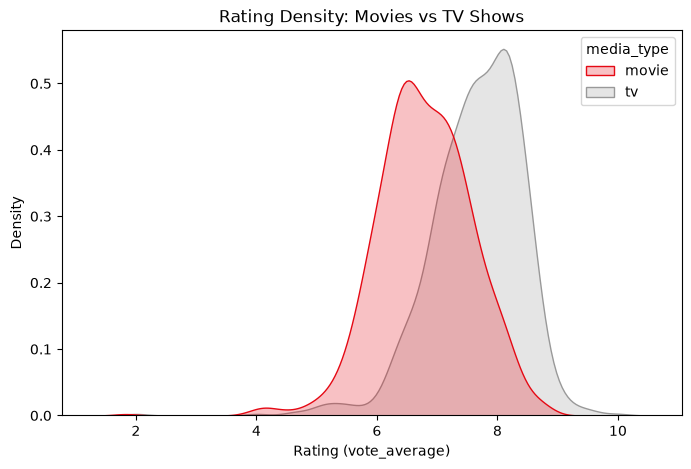

Insights
- 72% of titles are rated between 6 and 8, so most content sits in the middle-to-good range.
- Median rating by type: movie: 6.76, tv: 7.71.
- tv titles are rated higher by 0.94 points.
- Only 1% of titles score below 5, while 21% score 8 or higher.


In [2]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=titles.dropna(subset=["vote_average"]), x="vote_average",
            hue="media_type", fill=True, common_norm=False,
            palette={"movie": "#E50914", "tv": "#999999"})
plt.title("Rating Density: Movies vs TV Shows")
plt.xlabel("Rating (vote_average)")
plt.ylabel("Density")
plt.show()

rated = titles["vote_average"].dropna()
med = titles.groupby("media_type")["vote_average"].median()
share = rated.between(6, 8).mean() * 100
low = (rated < 5).mean() * 100
high = (rated >= 8).mean() * 100
print("Insights")
print(f"- {share:.0f}% of titles are rated between 6 and 8, so most content sits in the middle-to-good range.")
print("- Median rating by type: " + ", ".join(f"{k}: {v:.2f}" for k, v in med.items()) + ".")
if len(med) == 2:
    print(f"- {med.idxmax()} titles are rated higher by {med.max() - med.min():.2f} points.")
print(f"- Only {low:.0f}% of titles score below 5, while {high:.0f}% score 8 or higher.")

## Chart 10: Popularity vs rating

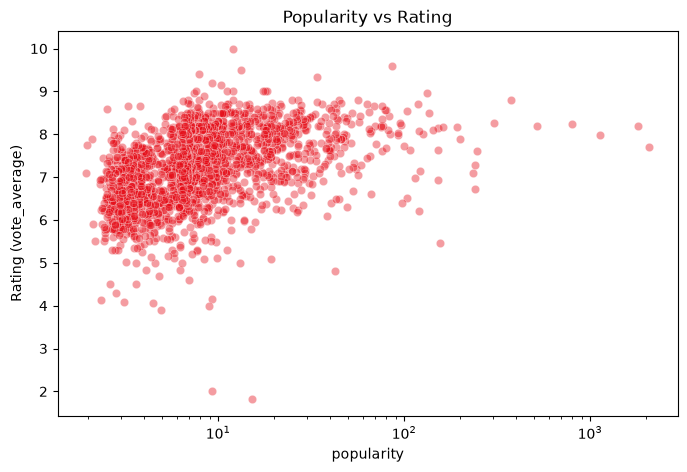

Insights
- There is a moderate positive relationship between popularity and rating (Spearman correlation = 0.51).
- The top 10% most popularity titles average 7.81, compared with 7.13 for the rest.
- The title with the highest popularity is The Flash (rating 7.7).


In [4]:
pop_col = "popularity" if "popularity" in titles.columns else "vote_count"

d = titles[[pop_col, "vote_average", "title"]].copy()
d[pop_col] = pd.to_numeric(d[pop_col], errors="coerce")
d["vote_average"] = pd.to_numeric(d["vote_average"], errors="coerce")
d = d.dropna(subset=[pop_col, "vote_average"])
d = d[d[pop_col] > 0]

plt.figure(figsize=(8, 5))
sns.scatterplot(data=d, x=pop_col, y="vote_average", alpha=0.4, color="#E50914")
plt.xscale("log")
plt.title(f"{pop_col.replace('_', ' ').title()} vs Rating")
plt.xlabel(pop_col)
plt.ylabel("Rating (vote_average)")
plt.show()

# Spearman correlation without scipy: Pearson correlation of the ranks
r = d[pop_col].rank().corr(d["vote_average"].rank())
strength = "weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.6 else "strong"
direction = "positive" if r > 0 else "negative"
cut = d[pop_col].quantile(0.9)
top_avg = d[d[pop_col] >= cut]["vote_average"].mean()
rest_avg = d[d[pop_col] < cut]["vote_average"].mean()
best = d.loc[d[pop_col].idxmax()]
label = pop_col.replace("_", " ")

print("Insights")
print(f"- There is a {strength} {direction} relationship between {label} and rating (Spearman correlation = {r:.2f}).")
print(f"- The top 10% most {label} titles average {top_avg:.2f}, compared with {rest_avg:.2f} for the rest.")
print(f"- The title with the highest {label} is {best['title']} (rating {best['vote_average']:.1f}).")

## Chart 11: Average rating by genre

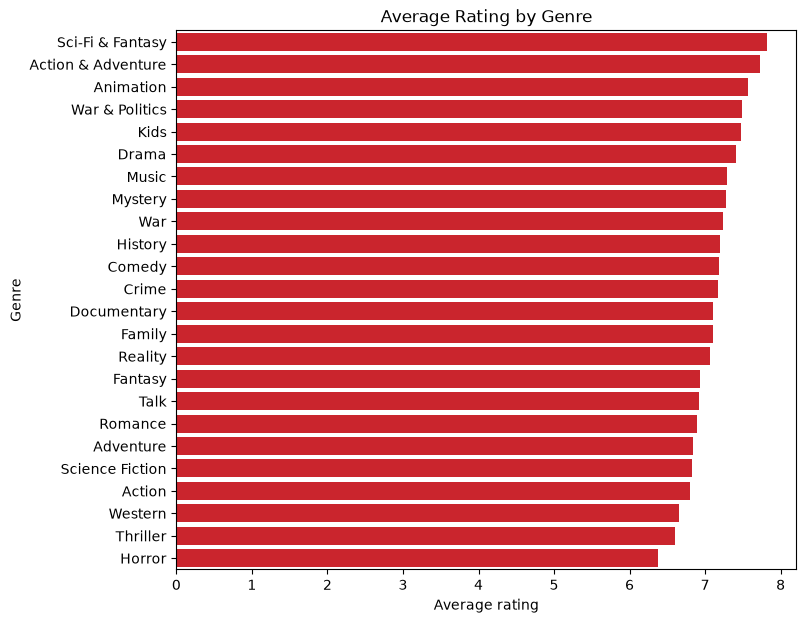

Insights
- Sci-Fi & Fantasy has the highest average rating (7.82) and Horror has the lowest (6.37), a gap of 1.44 points.
- 9 of 24 genres are rated above the overall average of 7.20.
- Only genres with at least 10 titles are shown, so small genres do not distort the result.


In [5]:
gr = (
    title_genres
    .merge(genres, on="genre_id")
    .merge(titles[["title_id", "vote_average"]], on="title_id")
)
avg = (
    gr.groupby("genre_name")["vote_average"]
    .agg(avg_rating="mean", n="count")
    .reset_index()
)
avg = avg[avg["n"] >= 10].sort_values("avg_rating", ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(data=avg, x="avg_rating", y="genre_name", color="#E50914")
plt.title("Average Rating by Genre")
plt.xlabel("Average rating")
plt.ylabel("Genre")
plt.show()

best, worst = avg.iloc[0], avg.iloc[-1]
overall = titles["vote_average"].mean()
above = int((avg["avg_rating"] > overall).sum())
print("Insights")
print(f"- {best['genre_name']} has the highest average rating ({best['avg_rating']:.2f}) and "
      f"{worst['genre_name']} has the lowest ({worst['avg_rating']:.2f}), a gap of "
      f"{best['avg_rating'] - worst['avg_rating']:.2f} points.")
print(f"- {above} of {len(avg)} genres are rated above the overall average of {overall:.2f}.")
print("- Only genres with at least 10 titles are shown, so small genres do not distort the result.")